# 05-0c — Low-complexity art : la beauté comme description courte (Schmidhuber 1997)

**Navigation** : [↑ 05-History](README.md) | [← 05-0 : Générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [05-1 : DiscoDiffusion →](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb)

> **Notebook rétrospectif — Racines pré-Stable-Diffusion.** Troisième jalon de
> l'[Epic #16774](https://github.com/jsboige/CoursIA/issues/16774), jointure avec
> l'[Epic #16775](https://github.com/jsboige/CoursIA/issues/16775) (curation Schmidhuber).
> Les deux jalons précédents ont **mesuré** qu'une description courte engendre une
> image riche : règles symboliques (05-0), puis intros de démoscène (05-0b, en
> revue dans la PR #20600). Ce
> carnet lit le texte qui a fait de cette mesure une **théorie esthétique**.

**Source** : J. Schmidhuber, « Low-Complexity Art », *Leonardo, Journal of the
International Society for the Arts, Sciences, and Technology*, vol. 30:2,
p. 97-103, MIT Press, 1997 (le frontispice porte « © J. Schmidhuber, 1994 »).
Copie lue pour ce carnet : `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\1997 - Schmidhuber - Low-Complexity Art.pdf`.

**La thèse, dans les mots du papier (§3)** : une œuvre de low-complexity art
doit atteindre deux buts à la fois.

- **But 1** : vu les spécifications, le dessin doit « avoir l'air juste ».
- **But 2** : (a) la complexité de Kolmogorov du dessin doit être petite :
  l'algorithme qui le calcule est court ; (b) un observateur informé doit
  pouvoir **percevoir** cette simplicité.

Le papier ne se contente pas de l'affirmer. Il donne un **schéma de codage**
précis, des cercles fractals régis par six règles, et il en tire des comptes.
Ce carnet reconstruit ce schéma, **vérifie ses comptes**, code des dessins en
bits et confronte la thèse à ces mesures.

**Plan**

1. Les règles des cercles légaux, appliquées à la lettre ;
2. vérifier les comptes du papier (12 cercles de rayon 1, 31 de rayon 1/2) ;
3. coder un dessin par numéros de cercles : le coût en bits ;
4. dessins, symétrie, et le contre-exemple des tout petits cercles ;
5. deux observateurs : le schéma des cercles contre les pixels ;
6. le style comme schéma partagé (équation 3 du papier) ;
7. exercices.

In [1]:
import math, itertools, io, lzma, zlib, inspect, random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle

EPS = 1e-9
plt.rcParams["figure.dpi"] = 90
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | matplotlib 3.11.1


## 1. Les règles des cercles légaux

Le §4.1 du papier définit les cercles « légaux ».

- **Initialisation** : un cercle de rayon et de centre arbitraires, puis un
  second de même rayon, centré sur un point du premier.
- **Règle 1** : partout où deux cercles légaux de même rayon se touchent ou se
  coupent, tracer un cercle légal de même rayon centré sur le point
  d'intersection.
- **Règle 2** : dans tout cercle légal de centre *p* et de rayon *r*, tracer un
  cercle légal de centre *p* et de rayon *r/2*.

La cellule suivante applique ces deux règles **littéralement** : la Règle 1 est
itérée jusqu'au point fixe dans une fenêtre bornée, et rien n'est supposé sur
la forme du résultat. Le cadre (le cercle initial) a le rayon 1. Un cercle est
**visible** s'il est couvert, au moins en partie, par le cadre.

In [2]:
def cle(p):
    """Cle de deduplication d'un centre (arrondi a 1e-6)."""
    return (round(p[0], 6), round(p[1], 6))

def intersections(c1, r1, c2, r2):
    """Points d'intersection (ou de contact) de deux cercles, 0, 1 ou 2 points."""
    (x1, y1), (x2, y2) = c1, c2
    d = math.hypot(x2 - x1, y2 - y1)
    if d < EPS or d > r1 + r2 + EPS or d < abs(r1 - r2) - EPS:
        return []
    a = (r1 * r1 - r2 * r2 + d * d) / (2 * d)
    h = math.sqrt(max(r1 * r1 - a * a, 0.0))
    mx, my = x1 + a * (x2 - x1) / d, y1 + a * (y2 - y1) / d
    ux, uy = -(y2 - y1) / d, (x2 - x1) / d
    if h < 1e-7:
        return [(mx, my)]
    return [(mx + h * ux, my + h * uy), (mx - h * ux, my - h * uy)]

def regle1_cloture(graines, r, fenetre):
    """Applique la Regle 1 jusqu'au point fixe : partout ou deux cercles legaux de
    rayon r se touchent ou se coupent, un nouveau cercle de rayon r est centre sur
    le point d'intersection. On borne la construction a |centre| <= fenetre."""
    centres = {cle(p): p for p in graines}
    change = True
    while change:
        change = False
        for a, b in itertools.combinations(list(centres.values()), 2):
            for q in intersections(a, r, b, r):
                if math.hypot(*q) <= fenetre + EPS and cle(q) not in centres:
                    centres[cle(q)] = q
                    change = True
    return list(centres.values())

# Initialisation du papier : un cercle de rayon 1 (le cadre), un second de meme
# rayon centre sur un point du premier.
niv = {}
niv[0] = regle1_cloture([(0.0, 0.0), (1.0, 0.0)], 1.0, 3.2)
# Regle 2 : dans chaque cercle legal de rayon r, un cercle de meme centre et de rayon r/2.
niv[1] = regle1_cloture(niv[0], 0.5, 2.2)
niv[2] = regle1_cloture(niv[1], 0.25, 1.4)

def visibles(centres, r, exclure_cadre=False):
    """Cercles (au moins partiellement) couverts par le cadre de rayon 1."""
    v = [p for p in centres if math.hypot(*p) < 1 + r - 1e-9]
    if exclure_cadre:
        v = [p for p in v if math.hypot(*p) > EPS]
    return v

n1 = len(visibles(niv[0], 1.0, exclure_cadre=True))
n2 = len(visibles(niv[1], 0.5))
n3 = len(visibles(niv[2], 0.25))
print(f"Rayon 1   : {n1} cercles visibles hors cadre   (papier : 12, numeros 2..13)")
print(f"Rayon 1/2 : {n2} cercles visibles               (papier : 31, numeros 14..44)")
print(f"Rayon 1/4 : {n3} cercles visibles               (le papier s'arrete a 1/2)")

Rayon 1   : 12 cercles visibles hors cadre   (papier : 12, numeros 2..13)
Rayon 1/2 : 31 cercles visibles               (papier : 31, numeros 14..44)
Rayon 1/4 : 85 cercles visibles               (le papier s'arrete a 1/2)


### Lecture : comptes du papier (12 et 31 cercles)

Les deux comptes du papier sont **reproduits à partir des seules règles** :
12 cercles visibles de rayon 1 hors cadre, numérotés 2 à 13, et 31 de rayon 1/2,
numérotés 14 à 44. Rien n'a été supposé sur la géométrie : la clôture de la
Règle 1 et l'application de la Règle 2 suffisent. Le niveau 1/4, que le papier
ne compte pas, porte 85 cercles visibles.

## 2. Ce que les règles engendrent : un réseau, à chaque échelle

Le papier ne nomme pas la structure que produisent les règles. On la teste : à
chaque niveau, l'ensemble des centres obtenu par clôture est-il exactement le
réseau triangulaire de pas *r* ? Si oui, on peut engendrer les niveaux plus fins
directement, sans répéter la clôture quadratique.

In [3]:
def reseau(pas, rayon_max):
    """Reseau triangulaire de pas donne, borne au disque |p| <= rayon_max."""
    pts = []
    k = int(rayon_max / pas) + 2
    for i in range(-2 * k, 2 * k + 1):
        for j in range(-2 * k, 2 * k + 1):
            x = pas * (i + 0.5 * j)
            y = pas * (j * math.sqrt(3) / 2)
            if math.hypot(x, y) <= rayon_max + EPS:
                pts.append((x, y))
    return pts

for n, (pts, fen) in enumerate([(niv[0], 3.2), (niv[1], 2.2), (niv[2], 1.4)]):
    r = 2.0 ** -n
    a = {cle(p) for p in pts if math.hypot(*p) <= fen + EPS}
    b = {cle(p) for p in reseau(r, fen)}
    print(f"niveau {n} (r={r:g}) : cloture des regles = reseau triangulaire de pas r ? {a == b} ({len(a)} centres)")

niveau 0 (r=1) : cloture des regles = reseau triangulaire de pas r ? True (37 centres)
niveau 1 (r=0.5) : cloture des regles = reseau triangulaire de pas r ? True (73 centres)
niveau 2 (r=0.25) : cloture des regles = reseau triangulaire de pas r ? True (121 centres)


### Lecture : reseau triangulaire de pas r

Aux trois niveaux testés, la clôture des règles est **exactement** le réseau
triangulaire de pas *r* (37, 73 et 121 centres dans les fenêtres choisies). Les
règles de Schmidhuber engendrent donc la grille de la « fleur de vie » à chaque
échelle. C'est ce constat, et lui seul, qui autorise la suite à engendrer les
niveaux plus fins directement par `reseau()`. Il est vérifié sur trois niveaux,
pas démontré pour tous.

Le commentaire 3 du §4.2 affirme que, sur une surface donnée, il y a « environ
quatre fois plus » de cercles de rayon 2^-(n+1) que de cercles de rayon 2^-n.
C'est une affirmation chiffrée, donc testable : on compte les cercles visibles
niveau par niveau.

In [4]:
comptes = []
for n in range(0, 8):
    r = 2.0 ** -n
    c = len([p for p in reseau(r, 1 + r) if math.hypot(*p) < 1 + r - 1e-9])
    if n == 0:
        c -= 1  # le cadre lui-meme porte le numero 1
    comptes.append((n, r, c))
print(" n   rayon     visibles   rapport au niveau precedent")
for i, (n, r, c) in enumerate(comptes):
    rap = "" if i == 0 else f"{c / comptes[i - 1][2]:.3f}"
    print(f"{n:2d}  {r:<8g}  {c:8d}   {rap}")

 n   rayon     visibles   rapport au niveau precedent
 0  1               12   
 1  0.5             31   2.583
 2  0.25            85   2.742
 3  0.125          295   3.471
 4  0.0625        1039   3.522
 5  0.03125       3943   3.795
 6  0.015625     15307   3.882
 7  0.0078125     60325   3.941


### Lecture : rapport entre niveaux (2,58 a 3,94)

Le rapport d'un niveau au suivant monte de **2,58** (rayon 1 → 1/2) à **3,94**
(1/64 → 1/128). Le « environ quatre fois plus » du papier est donc une
**limite**, atteinte par les petits cercles. Pour les gros cercles, ceux qui
coûtent le moins et dont le papier recommande l'usage, le facteur est voisin de
2,6. La raison est un effet de bord : un cercle de rayon *r* est visible dès que
son centre est à moins de 1 + *r* du centre, et la marge *r* pèse d'autant plus
que *r* est grand.

## 3. Coder un dessin par numéros de cercles

Le §4.3 numérote les cercles visibles : le cadre porte le 1, les cercles de
rayon 1 les numéros 2 à 13, ceux de rayon 1/2 les numéros 14 à 44, et ainsi de
suite. Les gros cercles ont donc de petits numéros. Un arc légal se code par
trois numéros : le cercle qui le porte, le cercle qui le coupe au départ, le
cercle qui le coupe à l'arrivée. S'y ajoutent un bit à chaque extrémité pour
choisir entre les deux intersections, et quelques bits pour l'épaisseur.

Le papier laisse deux choix ouverts, que ce carnet fixe et déclare :

- **l'ordre** des cercles de même rayon : « de façon déterministe, par exemple
  dans le sens horaire ». Ici, par distance au centre, puis par angle horaire
  depuis le haut.
- **le code des entiers** : le papier parle de « bits » sans fixer de code. Ici,
  un code d'Elias gamma, qui est préfixe : un flux de numéros se relit sans
  séparateur. Un numéro *n* y coûte 2⌊log₂ n⌋ + 1 bits.

In [5]:
def catalogue(profondeur):
    """Numerotation des cercles visibles : cadre = 1, puis par rayon decroissant ;
    a rayon egal, par distance au centre puis par angle dans le sens horaire depuis
    le haut (convention de ce carnet ; le papier dit seulement 'deterministe, par
    exemple dans le sens horaire')."""
    cat = [(1, (0.0, 0.0), 1.0)]
    for n in range(0, profondeur + 1):
        r = 2.0 ** -n
        pts = [p for p in reseau(r, 1 + r) if math.hypot(*p) < 1 + r - 1e-9]
        if n == 0:
            pts = [p for p in pts if math.hypot(*p) > EPS]
        def ordre(p):
            ang = (math.atan2(p[0], p[1])) % (2 * math.pi)  # horaire depuis le haut
            return (round(math.hypot(*p), 6), round(ang, 6))
        for p in sorted(pts, key=ordre):
            cat.append((len(cat) + 1, p, r))
    return cat

CAT = catalogue(4)
PAR_NUM = {num: (c, r) for num, c, r in CAT}
print("cercles numerotes jusqu'au rayon 1/16 :", len(CAT))
print("premiers numeros :", [(num, tuple(round(v, 3) for v in c), r) for num, c, r in CAT[:4]])
print("dernier rayon 1   :", max(n for n, c, r in CAT if r == 1.0),
      "| dernier rayon 1/2 :", max(n for n, c, r in CAT if r == 0.5))

cercles numerotes jusqu'au rayon 1/16 : 1463
premiers numeros : [(1, (0.0, 0.0), 1.0), (2, (0.5, 0.866), 1.0), (3, (1.0, 0.0), 1.0), (4, (0.5, -0.866), 1.0)]
dernier rayon 1   : 13 | dernier rayon 1/2 : 44


**Transition — du vocabulaire au prix**

Le catalogue qui précède fixe le **vocabulaire** : quels cercles existent, et sous quel numéro chacun — cadre = 1, puis par rayon décroissant (13 cercles de rayon 1, 31 de rayon 1/2, jusqu'à 1463 au rayon 1/16). La cellule suivante fixe le **prix de chaque mot** de ce vocabulaire. Un numéro seul ne suffit pas à coder un dessin : le décodeur doit aussi savoir où il finit. C'est ce que fait le code d'Elias gamma — un code **préfixe auto-délimité** dont la longueur 2⌊log₂ n⌋ + 1 double à chaque puissance de deux : gamma(1) = 1 bit, gamma(13) = 7, gamma(44) = 11, gamma(1000) = 19.

Un point mérite d'être vu avant de compter : la **validité** du schéma ne dépend pas de l'ordre de numérotation — n'importe quel ordre déterministe ferait un code décodable — mais son **économie**, si. C'est la convention « par rayon décroissant » qui met en tête de numérotation les cercles que le papier recommande d'utiliser (les grands), aux petits numéros donc au prix gamma faible. Avec une numérotation quelconque, un cercle de rayon 1 porterait typiquement un numéro voisin de 700, soit 19 bits au lieu de 7 : même schéma, même décodeur, dessins trois fois plus chers. Le tableau de coûts qui suit n'est donc pas un fait brut du monde des cercles : c'est la conséquence mesurée d'une convention, motivée mais choisie.
 Le papier n'impose rien d'autre de ce choix — « déterministe, par exemple dans le sens horaire » est sa seule contrainte, rappelée dans le docstring du catalogue.


In [6]:
def gamma_bits(n):
    """Longueur du code d'Elias gamma de l'entier n >= 1 (code prefixe, auto-delimite)."""
    return 2 * int(math.floor(math.log2(n))) + 1

def bits_arc(a):
    """Cout d'un arc legal (c, s, ks, e, ke, m) : numero du cercle porteur, numero du
    cercle qui le coupe au depart + 1 bit pour choisir entre les deux intersections,
    idem a l'arrivee, et l'epaisseur 2^-m codee par m+1. Un cercle complet est un
    arc (c, 0, 0, 0, 0, m) : un seul bit dit 'cercle complet'."""
    c, s, ks, e, ke, m = a
    if s == 0:
        return 1 + gamma_bits(c) + gamma_bits(m + 1)
    return 1 + gamma_bits(c) + gamma_bits(s) + 1 + gamma_bits(e) + 1 + gamma_bits(m + 1)

def point_extremite(c, s, k):
    (pc, rc), (ps, rs) = PAR_NUM[c], PAR_NUM[s]
    pts = sorted(intersections(pc, rc, ps, rs), key=lambda q: (round(q[0], 6), round(q[1], 6)))
    if not pts:
        raise ValueError(f"les cercles {c} et {s} ne se coupent pas")
    return pts[min(k, len(pts) - 1)]

def angle(pc, q):
    return math.degrees(math.atan2(q[1] - pc[1], q[0] - pc[0]))

def dessiner(arcs, ax, couleur="black", base=3.0):
    for a in arcs:
        c, s, ks, e, ke, m = a
        pc, rc = PAR_NUM[c]
        lw = base * 2.0 ** -m
        if s == 0:
            ax.add_patch(Circle(pc, rc, fill=False, lw=lw, color=couleur))
            continue
        qs, qe = point_extremite(c, s, ks), point_extremite(c, e, ke)
        # trace horaire de s vers e = trace anti-horaire de e vers s
        ax.add_patch(Arc(pc, 2 * rc, 2 * rc, theta1=angle(pc, qe), theta2=angle(pc, qs),
                         lw=lw, color=couleur))
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal"); ax.axis("off")

def cout(arcs):
    return sum(bits_arc(a) for a in arcs)
print("gamma(1), gamma(13), gamma(44), gamma(1000) :", [gamma_bits(n) for n in (1, 13, 44, 1000)])

gamma(1), gamma(13), gamma(44), gamma(1000) : [1, 7, 11, 19]


### Lecture : cout en bits du catalogue (1463 cercles)

Le catalogue jusqu'au rayon 1/16 compte 1463 cercles. Le cadre ne coûte qu'un
bit, un cercle de rayon 1 au plus 7 bits (numéro 13), un cercle de rayon 1/2 au
plus 11 bits (numéro 44), et un numéro voisin de 1000 en coûte 19. C'est la
traduction chiffrée du §4.3 : « plus les cercles sont grands, moins il faut de
bits ».

## 4. Des dessins, et ce qu'ils coûtent

Trois dessins construits avec les seules règles. La **rosace** utilise les six
cercles de rayon 1 qui passent par le centre. La même rosace est ensuite tracée
**à l'échelle 1/2**. Le **visage** prend ses yeux dans le niveau 1/4, ses
pupilles dans le niveau 1/16, et son sourire est un arc de rayon 1/2.

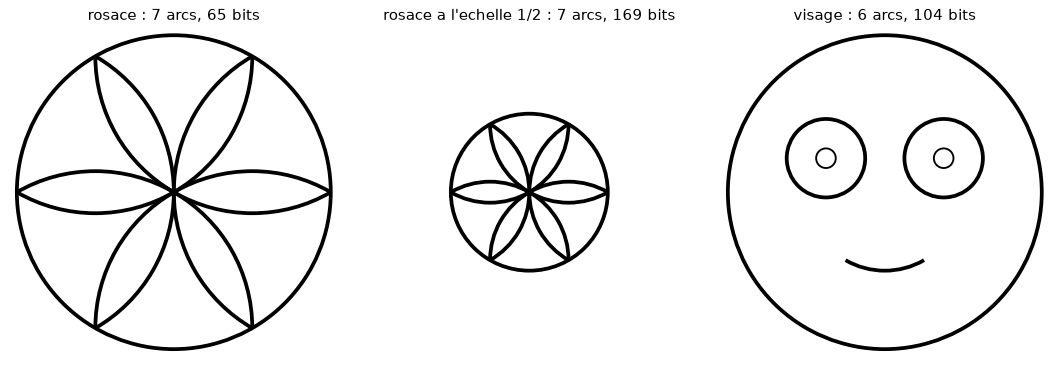

ROSACE         65 bits : [(1, 0, 0, 0, 0, 0), (3, 1, 0, 1, 1, 0), (2, 1, 1, 1, 0, 0), (7, 1, 1, 1, 0, 0), (6, 1, 1, 1, 0, 0), (5, 1, 0, 1, 1, 0), (4, 1, 0, 1, 1, 0)]
ROSACE_DEMI   169 bits : [(14, 0, 0, 0, 0, 0), (16, 14, 0, 14, 1, 0), (15, 14, 1, 14, 0, 0), (20, 14, 1, 14, 0, 0), (19, 14, 1, 14, 0, 0), (18, 14, 0, 14, 1, 0), (17, 14, 0, 14, 1, 0)]
VISAGE        104 bits : [(1, 0, 0, 0, 0, 0), (57, 0, 0, 0, 0, 0), (53, 0, 0, 0, 0, 0), (593, 0, 0, 0, 0, 1), (589, 0, 0, 0, 0, 1), (14, 29, 0, 30, 0, 0)]


In [7]:
def num_de(centre, r):
    """Numero du cercle legal de centre et rayon donnes."""
    for num, c, rr in CAT:
        if abs(rr - r) < EPS and math.hypot(c[0] - centre[0], c[1] - centre[1]) < 1e-6:
            return num
    raise KeyError((centre, r))

def arc_par(c, s, e, via):
    """Arc legal du cercle c, de son intersection avec s a son intersection avec e,
    passant par l'angle 'via' (degres, autour du centre de c). Le choix des deux bits
    de desambiguisation est fait ici, par le dessinateur : ce sont eux que le code paie."""
    pc, rc = PAR_NUM[c]
    for ks in (0, 1):
        for ke in (0, 1):
            try:
                a_s = angle(pc, point_extremite(c, s, ks)) % 360
                a_e = angle(pc, point_extremite(c, e, ke)) % 360
            except ValueError:
                continue
            if abs(a_s - a_e) < 1e-6:
                continue
            # arc horaire de a_s vers a_e : contient via si via est entre a_e et a_s en anti-horaire
            if (via - a_e) % 360 < (a_s - a_e) % 360:
                return (c, s, ks, e, ke, 0)
    raise ValueError(f"aucun arc de {c} entre {s} et {e} ne passe par {via}")

def cercle(c, m=0):
    return (c, 0, 0, 0, 0, m)

CADRE = cercle(1)
# Rosace : les six cercles de rayon 1 centres sur l'anneau 1 passent tous par le centre ;
# leur partie interieure au cadre trace six petales.
anneau = [num_de((math.cos(math.radians(a)), math.sin(math.radians(a))), 1.0) for a in range(0, 360, 60)]
ROSACE = [CADRE] + [arc_par(c, 1, 1, (math.degrees(math.atan2(-PAR_NUM[c][0][1], -PAR_NUM[c][0][0]))) % 360)
                    for c in anneau]

# Visage : deux yeux (rayon 1/4), deux pupilles (rayon 1/16), un sourire (arc du
# cercle de rayon 1/2 centre au milieu, borne par deux cercles de rayon 1/2 tangents).
# Meme rosace, a l'echelle 1/2 : meme forme, cercles plus petits.
anneau_demi = [num_de((0.5 * math.cos(math.radians(a)), 0.5 * math.sin(math.radians(a))), 0.5)
               for a in range(0, 360, 60)]
cadre_demi = num_de((0, 0), 0.5)
ROSACE_DEMI = [cercle(cadre_demi)] + [
    arc_par(c, cadre_demi, cadre_demi,
            (math.degrees(math.atan2(-PAR_NUM[c][0][1], -PAR_NUM[c][0][0]))) % 360)
    for c in anneau_demi]

s3 = math.sqrt(3) / 2
oeil_g, oeil_d = (-0.375, 0.25 * s3), (0.375, 0.25 * s3)
VISAGE = [CADRE,
          cercle(num_de(oeil_g, 0.25)), cercle(num_de(oeil_d, 0.25)),
          cercle(num_de(oeil_g, 0.0625), 1), cercle(num_de(oeil_d, 0.0625), 1),
          arc_par(num_de((0, 0), 0.5), num_de((0.5, -2 * 0.5 * s3), 0.5),
                  num_de((-0.5, -2 * 0.5 * s3), 0.5), 270)]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (nom, d) in zip(axes, [("rosace", ROSACE), ("rosace a l'echelle 1/2", ROSACE_DEMI), ("visage", VISAGE)]):
    dessiner(d, ax)
    ax.set_title(f"{nom} : {len(d)} arcs, {cout(d)} bits")
plt.tight_layout(); plt.show()
for nom, d in [("ROSACE", ROSACE), ("ROSACE_DEMI", ROSACE_DEMI), ("VISAGE", VISAGE)]:
    print(f"{nom:12s} {cout(d):4d} bits : {d}")

### Lecture : cout en bits des trois dessins

- La **rosace** coûte **65 bits** pour sept éléments : tous ses arcs commencent
  et finissent sur le cadre, le cercle numéro 1, qui est le moins cher.
- La **même rosace à l'échelle 1/2** coûte **169 bits**, soit 2,6 fois plus,
  pour une forme identique : ses cercles portent les numéros 14 à 20 au lieu
  de 1 à 7.
- Dans le **visage** (104 bits), les deux pupilles (numéros 589 et 593, rayon
  1/16) coûtent 23 bits chacune. Ces deux petits points font **44 %** du coût
  du dessin, et les deux yeux qui les entourent n'en font que 13 bits chacun.

Le schéma récompense donc les grands traits, et il pénalise le détail fin plus
que la forme d'ensemble.

Le papier note (§4.3) que l'artiste exploitera souvent des symétries propres au
dessin pour compresser encore la description. La rosace est invariante par
rotation de 60°, et cette rotation envoie chaque niveau du réseau sur lui-même :
un pétale tourné reste un arc légal. On le mesure.

In [8]:
# La rosace est invariante par rotation de 60 degres, et cette rotation envoie le
# reseau de chaque niveau sur lui-meme : un petale tourne reste un arc legal.
# Instruction 'repete k fois en tournant de 360/k' : 2 bits d'opcode + gamma(k).
def cout_symetrique(fixes, motif, k):
    return cout(fixes) + cout(motif) + 2 + gamma_bits(k)

c_sym = cout_symetrique([CADRE], [ROSACE[1]], 6)
print(f"rosace, six petales ecrits       : {cout(ROSACE)} bits")
print(f"rosace, un petale + 'repete x6'  : {c_sym} bits")

rosace, six petales ecrits       : 65 bits
rosace, un petale + 'repete x6'  : 19 bits


### Lecture : compression par symetrie (gain x3,4)

Écrire un seul pétale et l'instruction « répète six fois » fait passer la
rosace de **65 à 19 bits**, soit un gain d'un facteur 3,4. C'est la compression
par symétrie propre au dessin que le §4.3 annonce. Elle ne coûte rien en
légalité : une rotation de 60° envoie chaque niveau du réseau sur lui-même.

Le §4.3 donne aussi le contre-exemple : « avec beaucoup de très petits cercles,
on peut tout dessiner », mais cela demande beaucoup d'information. On retrace la
rosace avec les cercles de rayon 1/16 les plus proches de son tracé. Un témoin
s'y ajoute : six arcs tirés **au hasard** (graine fixe) parmi les treize mêmes
premiers cercles, de sorte qu'ils restent dans le cadre.

In [9]:
# Le contre-exemple du papier : avec assez de tres petits cercles, on peut tout
# dessiner -- mais chaque petit cercle a un grand numero, donc coute cher.
def echantillonner(arcs, n_par_arc=400):
    pts = []
    for c, s, ks, e, ke, m in arcs:
        pc, rc = PAR_NUM[c]
        if s == 0:
            t = np.linspace(0, 2 * math.pi, n_par_arc, endpoint=False)
        else:
            a1 = math.radians(angle(pc, point_extremite(c, s, ks)))
            a2 = math.radians(angle(pc, point_extremite(c, e, ke)))
            t = np.linspace(a1, a1 - ((a1 - a2) % (2 * math.pi)), n_par_arc)
        pts += list(zip(pc[0] + rc * np.cos(t), pc[1] + rc * np.sin(t)))
    return pts

def en_petits_cercles(arcs, r):
    """Remplace chaque arc par les cercles legaux de rayon r les plus proches du trace."""
    centres = [(num, c) for num, c, rr in CAT if abs(rr - r) < EPS]
    arr = np.array([c for _, c in centres])
    choisis = set()
    for p in echantillonner(arcs):
        i = int(np.argmin(((arr - np.array(p)) ** 2).sum(axis=1)))
        choisis.add(centres[i][0])
    return [cercle(n, 3) for n in sorted(choisis)]

ROSACE_GRAINS = en_petits_cercles(ROSACE, 0.0625)
print(f"rosace en cercles de rayon 1/16 : {len(ROSACE_GRAINS)} cercles, {cout(ROSACE_GRAINS)} bits "
      f"(numeros de {ROSACE_GRAINS[0][0]} a {ROSACE_GRAINS[-1][0]})")

rosace en cercles de rayon 1/16 : 357 cercles, 9179 bits (numeros de 425 a 1427)


**Ce que le contrôle isole**

La cellule précédente a fait varier le **matériau** : la même rosace, retracée en cercles de rayon 1/16. Le contrôle fait l'opération duale — il **fixe** le matériau et ne laisse varier que l'**arrangement** : six arcs tirés au hasard (graine 1997) parmi les mêmes treize premiers cercles que ceux de la rosace, avec le même budget de sept éléments, et pour seules contraintes d'être traçables (extrémités éloignées de plus de 0,3, tracé contenu dans le disque). Si le compteur de bits ne mesurait que le matériau, ce tirage et la rosace tomberaient au même prix. La figure affiche les cinq dessins sous un même titre — nombre d'éléments, coût en bits — pour que l'œil et le compteur jugent ensemble, et la lecture qui suit chiffre l'écart.
 La graine 1997 rend le tirage rejouable : le témoin n'est pas une moyenne mais un exemplaire figé, consultable à l'identique à chaque exécution.


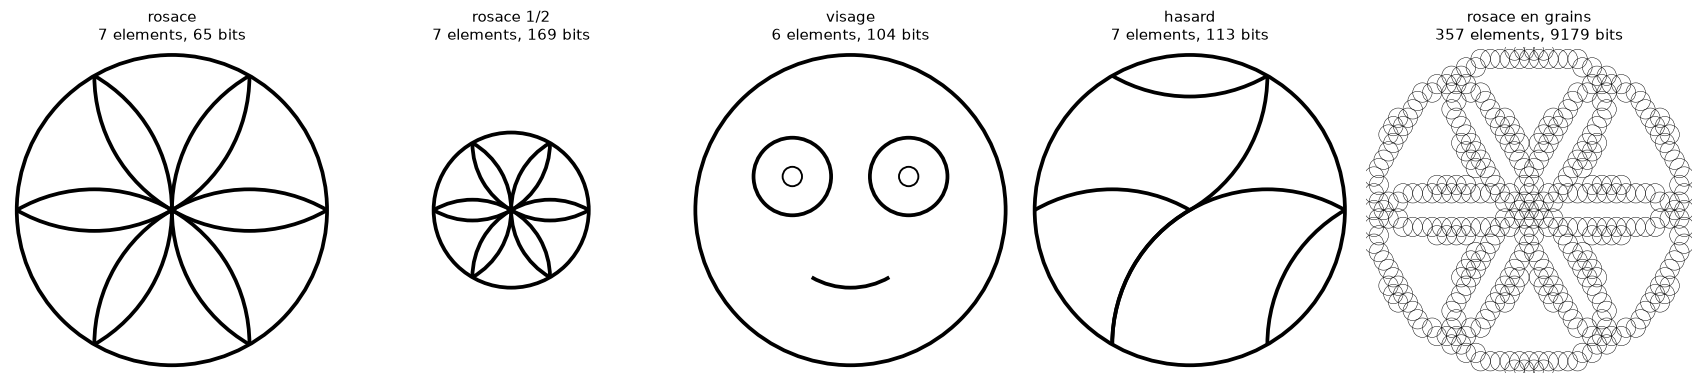

In [10]:
# Controle : sept arcs tires au hasard parmi les memes treize premiers cercles.
rng = random.Random(1997)
def arc_aleatoire():
    while True:
        c, s, e = rng.randint(2, 13), rng.randint(1, 13), rng.randint(1, 13)
        ks, ke = rng.randint(0, 1), rng.randint(0, 1)
        try:
            qs, qe = point_extremite(c, s, ks), point_extremite(c, e, ke)
        except ValueError:
            continue
        a = (c, s, ks, e, ke, 0)
        if math.dist(qs, qe) > 0.3 and all(math.hypot(*p) <= 1 + 1e-6 for p in echantillonner([a], 60)):
            return a
HASARD = [CADRE] + [arc_aleatoire() for _ in range(6)]

dessins = {"rosace": ROSACE, "rosace 1/2": ROSACE_DEMI, "visage": VISAGE, "hasard": HASARD, "rosace en grains": ROSACE_GRAINS}
fig, axes = plt.subplots(1, 5, figsize=(19, 4.6))
for ax, (nom, d) in zip(axes, dessins.items()):
    dessiner(d, ax)
    ax.set_title(f"{nom}\n{len(d)} elements, {cout(d)} bits")
plt.tight_layout(); plt.show()

### Lecture : le contre-exemple en chiffres (141x)

- **Le contre-exemple du papier, chiffré.** La rosace retracée en cercles de
  rayon 1/16 demande **357 cercles** et **9179 bits**, soit 141 fois le tracé
  en grands arcs. La forme est la même, même si les grains la rendent plus
  rugueuse. Avec assez de petits cercles on peut tout dessiner, mais cela
  coûte une fortune en information, et c'est pour cela que ce n'est « pas
  impressionnant ».
- **Le témoin du hasard.** Six arcs aléatoires pris dans les treize mêmes
  cercles coûtent **113 bits**. C'est à peine plus que le visage (104 bits),
  alors que le hasard ne représente rien. Une description courte est donc
  **nécessaire** au low-complexity art, **pas suffisante** : le But 1 (« avoir
  l'air juste ») n'est pas mesuré par les bits. Le papier le dit lui-même
  (§3.1 : le But 1 est la part subjective), et la mesure le confirme.

## 5. Deux observateurs : le schéma des cercles contre les pixels

Au §6.1, la beauté est **relative à l'observateur** : elle dépend de
l'algorithme de codage *C* qu'il porte. On instancie deux observateurs.

- Le premier connaît le **schéma des cercles** : il paie les bits du code des
  arcs.
- Le second ne connaît que des **pixels** : il paie l'image rendue en 256×256
  sur 1 bit, compressée par LZMA (et, pour référence, par PNG).

In [11]:
def bitmap(arcs, taille=256):
    fig = plt.figure(figsize=(1, 1), dpi=taille)
    ax = fig.add_axes([0, 0, 1, 1])
    dessiner(arcs, ax, base=1.0)
    fig.canvas.draw()
    img = np.asarray(fig.canvas.buffer_rgba())[:, :, 0]
    plt.close(fig)
    return (img < 128).astype(np.uint8)

def bits_png(b):
    buf = io.BytesIO()
    plt.imsave(buf, b, cmap="gray_r", format="png")
    return 8 * len(buf.getvalue())

def bits_lzma(b):
    return 8 * len(lzma.compress(np.packbits(b).tobytes(), preset=9))

print(f"{'dessin':18s} {'cercles':>8s} {'LZMA 1 bit':>11s} {'PNG':>8s} {'brut':>7s}  ratio LZMA/cercles")
lignes = []
for nom, d in dessins.items():
    b = bitmap(d)
    lignes.append((nom, cout(d), bits_lzma(b), bits_png(b), b.size))
    print(f"{nom:18s} {cout(d):8d} {bits_lzma(b):11d} {bits_png(b):8d} {b.size:7d}  x{bits_lzma(b) / cout(d):.0f}")

dessin              cercles  LZMA 1 bit      PNG    brut  ratio LZMA/cercles
rosace                   65       10144    31096   65536  x156
rosace 1/2              169        5632    19080   65536  x33
visage                  104        8768    24288   65536  x84


hasard                  113       10560    25680   65536  x93


rosace en grains       9179       11680    42896   65536  x1


### Lecture : inversion des classements (cercles vs pixels)

Les deux observateurs ne voient pas les mêmes dessins.

| Comparaison | Observateur « cercles » | Observateur « pixels » (LZMA) |
|---|---|---|
| rosace en grains contre rosace | **141 fois** plus cher (9179 contre 65 bits) | 1,15 fois plus cher (11680 contre 10144 bits) |
| rosace 1/2 contre rosace | **2,6 fois plus cher** (169 contre 65 bits) | **1,8 fois moins cher** (5632 contre 10144 bits) |

Sur les deux rosaces, les classements sont **inversés**. L'observateur des
pixels paie l'encre, et la petite rosace en a moins. L'observateur des cercles
paie les numéros, et la petite rosace utilise des cercles plus petits. C'est la
thèse du §6.1, mesurée : la longueur de description, et donc la « beauté »
qu'on en dérive, n'est pas une propriété du dessin seul, mais du couple dessin
et codage de l'observateur. Pour l'observateur des pixels, aucun dessin ne
descend sous 5600 bits, et le surcoût fixe du conteneur LZMA en fait partie.
Pour lui, l'écart entre une rosace en trois traits et sa version en grains est
de 15 % : la simplicité algorithmique du dessin lui est invisible.

## 6. Le style comme schéma partagé

Le §6.2 définit la qualité d'un style *C* par l'équation (3) : *C* est bon s'il
minimise la somme de deux termes. Le premier est l'information nécessaire pour
calculer les dessins *S* à partir de *C*. Le second est l'information nécessaire
pour calculer *C* à partir de ce que sait déjà l'observateur. Le §5 en tire une
conséquence : coder plusieurs dessins **ensemble** coûte moins cher que les
coder séparément, parce que le schéma est payé une seule fois. On mesure L(*C*)
par la taille compressée du code source des fonctions du schéma.

In [12]:
# Equation (3) du papier : un style C est bon s'il minimise
#   -log P(S|C) - log P(C)  =  L(S|C) + L(C)  (en bits),
# la longueur des dessins sachant le schema, plus la longueur du schema lui-meme.
# L(C) se mesure ici par la taille compressee du code source du schema.
FONCTIONS_SCHEMA = [intersections, regle1_cloture, reseau, catalogue,
                    gamma_bits, bits_arc, point_extremite, angle, dessiner]
source = chr(10).join(inspect.getsource(f) for f in FONCTIONS_SCHEMA)
L_C = 8 * len(lzma.compress(source.encode("utf-8"), preset=9))
print(f"schema des cercles : {len(source)} caracteres de source, L(C) = {L_C} bits (LZMA)")

corpus = {"rosace": ROSACE, "visage": VISAGE, "rosace a l'echelle 1/2": ROSACE_DEMI}
separes = sum(L_C + cout(d) for d in corpus.values())
ensemble = L_C + sum(cout(d) for d in corpus.values())
print(f"trois dessins codes separement : {separes} bits")
print(f"trois dessins codes ensemble   : {ensemble} bits  (le schema est paye une fois)")
print(f"information mutuelle partagee  : {separes - ensemble} bits = 2 x L(C)")

schema des cercles : 4231 caracteres de source, L(C) = 14816 bits (LZMA)
trois dessins codes separement : 44786 bits
trois dessins codes ensemble   : 15154 bits  (le schema est paye une fois)
information mutuelle partagee  : 29632 bits = 2 x L(C)


### Lecture : economie du schema (44x les trois dessins)

Le schéma des cercles coûte **L(C) = 14816 bits** à qui ne le connaît pas.
C'est **44 fois** le coût des trois dessins réunis (338 bits). Payé une fois
pour trois dessins, le total tombe de 44786 à 15154 bits. Que l'économie vaille
exactement deux fois L(C) découle de la construction : c'est le schéma payé
deux fois de moins. Ce qui est mesuré, c'est l'**ordre de grandeur**.

Le §6.2 conclut que le schéma des cercles est un « bon » style parce qu'il est
facile à enseigner, si bien que le second terme de l'équation (3) serait
négligeable. La mesure précise la portée de cette conclusion. Elle vaut pour un
observateur qui a **déjà appris** le schéma. Pour un observateur qui le
découvre, le schéma domine la facture de plusieurs ordres de grandeur, et il ne
s'amortit qu'au fil de nombreux dessins. Ici, L(C) est un majorant grossier :
c'est la taille compressée d'un code Python commenté, pas celle du plus court
programme. C'est néanmoins la seule grandeur de ce carnet que le papier ne
fournit pas.

**Le point de croisement des deux observateurs.** Ces nombres permettent aussi de chiffrer *quand* il devient rentable d'avoir appris le schéma. Pour un observateur qui le connaît, la rosace coûte 65 bits — dérisoire devant les 10144 bits de l'observateur pixel. Mais pour un premier dessin, l'apprentissage n'est pas amorti : 14816 + 65 = 14881 bits, et le schéma **perd** contre les pixels. Dès le deuxième dessin codé ensemble, 14816 + 130 = 14946 bits contre 2 × 10144 = 20288 : le schéma gagne, et l'écart croît à chaque dessin (une centaine de bits d'un côté, dix mille de l'autre). C'est la lecture chiffrée du « facile à enseigner » du §6.2 : amortissement rapide signifie, dans ce carnet, **deux dessins**.


## 7. Exercices

Ce que chaque exercice mesure, pour le vérifier vous-même :

1. **Le commentaire 1** — c'est une vérification d'énoncé, pas une préférence : sur chaque cercle de rayon 1/2 puis 1/4 du catalogue, compter les centres de même rayon à distance exactement *r*. Le verdict est un nombre — et c'est six, ou ce n'est pas six.
2. **Le dessin le moins cher** — la question de fond n'est pas « pouvez-vous dessiner » mais **quelles formes sont intrinsèquement bon marché** : battre le visage (104 bits) en choisissant des arcs sur les gros cercles (numéros petits) et, comme la rosace, en commençant et finissant les arcs sur le cercle le moins cher du catalogue.
3. **Le miroir** — il réplique la démarche de la section 4 pour une autre symétrie, et dans le même ordre : d'abord établir la **légalité** (le miroir gauche-droite envoie-t-il chaque niveau du réseau sur lui-même ? sans ça, l'opcode n'a pas de sens), puis chiffrer le gain d'un motif écrit une fois.

Dans les trois cas, la réponse est un nombre mesuré par un compteur — `cout(...)` ou un décompte — jamais une impression : c'est la discipline de ce carnet.


In [13]:
# Exercice 1 - le commentaire 1 du papier
# Le §4.2 affirme : « sur chaque cercle légal, on trouve les centres de six cercles
# légaux de même rayon ». Le vérifier pour les cercles de rayon 1/2 et 1/4 du catalogue.
# # Indice 1 - un centre q est sur le cercle (p, r) si |q - p| = r à 1e-9 près ;
# # Etape 1 - parcourir CAT ; # Etape 2 - compter les centres de même rayon à distance r.
print("Exercice 1 a completer")

Exercice 1 a completer


In [14]:
# Exercice 2 - le dessin le moins cher
# Concevoir un dessin reconnaissable (un poisson, une lune, une fleur) qui coûte
# MOINS de bits que VISAGE. Mesurer cout(...) et afficher le rendu avec dessiner().
# # Indice 1 - les petits numéros sont les gros cercles : préférer les rayons 1 et 1/2 ;
# # Etape 1 - choisir les arcs avec arc_par ; # Etape 2 - mesurer ; # Etape 3 - regarder.
print("Exercice 2 a completer")

Exercice 2 a completer


In [15]:
# Exercice 3 - le visage symétrique
# VISAGE a une symétrie gauche-droite. Définir une instruction 'miroir' (coût : 2 bits
# d'opcode) qui duplique les éléments de gauche, et mesurer le gain comme en 4.
# # Indice 1 - le miroir envoie-t-il chaque niveau du réseau sur lui-même ? Le vérifier d'abord ;
# # Etape 1 - lister les éléments à dupliquer ; # Etape 2 - écrire le coût.
print("Exercice 3 a completer")

Exercice 3 a completer


## 8. Conclusion

Ce jalon a reconstruit le schéma des cercles fractals de Schmidhuber et l'a
mesuré.

- **Ce qui tient.** Les comptes du papier (12 et 31) se reproduisent depuis les
  règles seules, et les règles engendrent un réseau triangulaire à chaque
  échelle. Le codage par numéros récompense bien les grands traits : une rosace
  coûte 65 bits, sa version en grains 9179, et une symétrie la ramène à 19.
- **Ce que la mesure précise.**
  - Le facteur « environ quatre » entre niveaux est une limite, voisine de 2,6
    pour les gros cercles.
  - Une description courte ne distingue pas un dessin juste d'un dessin quelconque : le visage
    coûte 104 bits, le hasard 113.
  - Le style n'est « bon marché » que pour qui l'a déjà appris : le schéma lui-même coûte 44 fois les
    dessins qu'il code.
- **Ce qui ressort le plus nettement.** Changer d'observateur, en passant des
  cercles aux pixels, inverse le classement de deux rosaces de même forme.
  C'est la relativité à l'observateur du §6.1, rendue mesurable.

Le fil de la longueur de description continue dans le rayon : la CLIP-guided
diffusion (05-1) et CLIPasso (05-2) remplaceront le schéma écrit à la main par
une mesure apprise, et c'est un observateur appris qui jugera du « juste ».

**Rattachements** : Epic #16774 (jalon 3) · Epic #16775 (curation Schmidhuber,
source D1) · jalons précédents : [05-0](05-0-Generateurs-Symboliques.ipynb) et 05-0b (PR #20600).